# Part 1: Dataset Acquisition

Load SemCor and WordNet, then collect annotated words and their senses.


In [1]:
# Kaggle already includes PyTorch. Install the notebook libraries before importing them.
%pip install -q "transformers>=4.44,<5" "nltk>=3.9,<4" "scikit-learn>=1.5,<2" pandas joblib tqdm matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json
import random
import unicodedata
import gc

import joblib
import nltk
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display
from nltk.corpus import semcor, wordnet as wn
from nltk.corpus.reader.wordnet import Lemma
from nltk.tree import Tree
from tqdm.auto import tqdm

SEED = 42
OUT = Path("/kaggle/working/wsd_simple")
for folder in ["artifacts", "data", "evaluation"]:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Output folder:", OUT)


Device: cuda
Output folder: /kaggle/working/wsd_simple


In [3]:
nltk.download("semcor")
nltk.download("wordnet")

phrases = semcor.sents()
phrases_annotees = semcor.tagged_sents(tag="sem")

print("Number of sentences:", len(phrases))
print(phrases_annotees[0])


[nltk_data] Downloading package semcor to /usr/share/nltk_data...
[nltk_data]   Package semcor is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Number of sentences: 37176
[['The'], Tree(Lemma('group.n.01.group'), [Tree('NE', ['Fulton', 'County', 'Grand', 'Jury'])]), Tree(Lemma('state.v.01.say'), ['said']), Tree(Lemma('friday.n.01.Friday'), ['Friday']), ['an'], Tree(Lemma('probe.n.01.investigation'), ['investigation']), ['of'], Tree(Lemma('atlanta.n.01.Atlanta'), ['Atlanta']), ["'s"], Tree(Lemma('late.s.03.recent'), ['recent']), Tree(Lemma('primary.n.01.primary_election'), ['primary', 'election']), Tree(Lemma('produce.v.04.produce'), ['produced']), ['``'], ['no'], Tree(Lemma('evidence.n.01.evidence'), ['evidence']), ["''"], ['that'], ['any'], Tree(Lemma('abnormality.n.04.irregularity'), ['irregularities']), Tree(Lemma('happen.v.01.take_place'), ['took', 'place']), ['.']]


In [4]:
rows = []
sentence_tokens = {}
unlabelled_items = 0

for sentence_id, annotated_sentence in enumerate(tqdm(phrases_annotees)):
    words = []
    annotations = []

    for item in annotated_sentence:
        tokens = item.leaves() if isinstance(item, Tree) else list(item)
        position = len(words)
        words.extend(tokens)

        if not isinstance(item, Tree) or not isinstance(item.label(), Lemma):
            unlabelled_items += 1
            continue
        if not tokens or not any(c.isalnum() for word in tokens for c in word):
            continue

        label = item.label()
        sense = label.synset()
        annotations.append({
            "sentence_id": sentence_id,
            "target_word": " ".join(tokens),
            "target_position": position,
            "target_end": len(words),
            "lemma": label.name().lower(),
            "pos": "a" if sense.pos() == "s" else sense.pos(),
            "sense": sense.name()
        })

    assert words == list(phrases[sentence_id]), "Sentence tokens do not match."
    sentence_tokens[sentence_id] = words
    for annotation in annotations:
        annotation["sentence"] = " ".join(words)
        rows.append(annotation)

df = pd.DataFrame(rows)
print("Annotated targets:", len(df))
print("Items without a resolved sense:", unlabelled_items)
display(df.head())


  0%|          | 0/37176 [00:00<?, ?it/s]

Annotated targets: 224714
Items without a resolved sense: 553871


,sentence_id,target_word,target_position,target_end,lemma,pos,sense,sentence
0,0,Fulton County Grand Jury,1,5,group,n,group.n.01,The Fulton County Grand Jury said Friday an in...
1,0,said,5,6,say,v,state.v.01,The Fulton County Grand Jury said Friday an in...
2,0,Friday,6,7,friday,n,friday.n.01,The Fulton County Grand Jury said Friday an in...
3,0,investigation,8,9,investigation,n,probe.n.01,The Fulton County Grand Jury said Friday an in...
4,0,Atlanta,10,11,atlanta,n,atlanta.n.01,The Fulton County Grand Jury said Friday an in...


Unlike the reference notebook's two-observed-senses filter, we keep all valid labels.
This preserves rare senses and avoids using test labels to choose the vocabulary.
A target may contain several words; target_end is the first index after the target.


In [5]:
columns = ["sentence_id", "target_position", "target_end", "lemma", "pos"]
duplicates = df.duplicated(columns + ["sense"])
print("Exact duplicate annotations removed:", duplicates.sum())
df = df.loc[~duplicates].reset_index(drop=True)

conflicts = df.groupby(columns)["sense"].transform("nunique") > 1
print("Conflicting annotations retained:", conflicts.sum())
df.loc[conflicts].to_csv(OUT / "data/conflicting_annotations.csv", index=False)
df.to_csv(OUT / "data/semcor_wsd.csv", index_label="example_id")

del rows, phrases, phrases_annotees
gc.collect()


Exact duplicate annotations removed: 0
Conflicting annotations retained: 0


15984

# Part 2: Text Preprocessing

Keep punctuation, negation, stopwords, and word order. Normalize quotes and brackets without changing target positions.


In [6]:
TOKEN_MAP = {
    "``": '"', "''": '"', "-LRB-": "(", "-RRB-": ")",
    "-LSB-": "[", "-RSB-": "]", "-LCB-": "{", "-RCB-": "}"
}
CHAR_MAP = str.maketrans({
    "\u2018": "'", "\u2019": "'", "\u201c": '"',
    "\u201d": '"', "\u2013": "-", "\u2014": "-"
})

def normalize_token(token):
    token = unicodedata.normalize("NFKC", token).translate(CHAR_MAP)
    token = TOKEN_MAP.get(token, token).strip()
    return token if token else "[UNK]"

def sentence_group(words):
    # Ignore case and punctuation only when identifying repeated sentences.
    content = []
    for word in words:
        word = "".join(c for c in normalize_token(word).casefold() if c.isalnum())
        if word:
            content.append(word)
    return " ".join(content)


In [7]:
processed = {}
for sentence_id, words in sentence_tokens.items():
    processed[sentence_id] = [normalize_token(word) for word in words]

df["tokens"] = df["sentence_id"].map(processed)
df["clean_sentence"] = df["tokens"].map(" ".join)
df["clean_target_position"] = df["target_position"]
df["sentence_group"] = df["tokens"].map(sentence_group)

for row in df.itertuples():
    assert 0 <= row.target_position < row.target_end <= len(row.tokens)
    original = sentence_tokens[row.sentence_id][row.target_position:row.target_end]
    assert " ".join(original) == row.target_word
    assert len(row.tokens) == len(sentence_tokens[row.sentence_id])

display(df[["sentence", "clean_sentence", "target_word", "target_position"]].head())


,sentence,clean_sentence,target_word,target_position
0,The Fulton County Grand Jury said Friday an in...,The Fulton County Grand Jury said Friday an in...,Fulton County Grand Jury,1
1,The Fulton County Grand Jury said Friday an in...,The Fulton County Grand Jury said Friday an in...,said,5
2,The Fulton County Grand Jury said Friday an in...,The Fulton County Grand Jury said Friday an in...,Friday,6
3,The Fulton County Grand Jury said Friday an in...,The Fulton County Grand Jury said Friday an in...,investigation,8
4,The Fulton County Grand Jury said Friday an in...,The Fulton County Grand Jury said Friday an in...,Atlanta,10


### Separate training, validation, and test sentences

Use approximately 64% / 16% / 20% of sentence groups.
Repeated sentence content stays in one partition. Only fit rows train BERT, the scaler,
and Logistic Regression. Validation selects the BERT checkpoint; test rows are evaluated at the end.


In [8]:
from sklearn.model_selection import GroupShuffleSplit

outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_indices, test_indices = next(outer.split(df, groups=df["sentence_group"]))
train_df = df.iloc[train_indices]
test_df = df.iloc[test_indices]

inner = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
fit_positions, val_positions = next(
    inner.split(train_df, groups=train_df["sentence_group"])
)
fit_df = train_df.iloc[fit_positions]
val_df = train_df.iloc[val_positions]

for left, right in [(fit_df, val_df), (fit_df, test_df), (val_df, test_df)]:
    assert set(left["sentence_group"]).isdisjoint(right["sentence_group"])
    assert set(left["sentence_id"]).isdisjoint(right["sentence_id"])

df["split"] = "test"
df.loc[fit_df.index, "split"] = "fit"
df.loc[val_df.index, "split"] = "validation"
print("Fit:", len(fit_df), "| Validation:", len(val_df), "| Test:", len(test_df))


Fit: 142782 | Validation: 36349 | Test: 45583


In [9]:
# Save tokens as JSON so their boundaries can be restored exactly.
saved_df = df.copy()
saved_df["tokens"] = saved_df["tokens"].map(json.dumps)
saved_df.to_csv(OUT / "data/semcor_wsd_preprocessed.csv", index_label="example_id")
df[["sentence_id", "target_position", "target_end", "lemma", "pos", "sense", "split"]].to_csv(
    OUT / "data/split_manifest.csv", index_label="example_id"
)
del saved_df

# All sense counts and training weights come from fit rows only.
frequencies = fit_df.groupby(["lemma", "pos", "sense"]).size().rename("count").reset_index()
maximum = frequencies.groupby(["lemma", "pos"])["count"].transform("max")
frequencies["weight"] = np.sqrt(maximum / frequencies["count"]).clip(upper=3.0)
frequency_lookup = frequencies.set_index(["lemma", "pos", "sense"])["count"].to_dict()
weight_lookup = frequencies.set_index(["lemma", "pos", "sense"])["weight"].to_dict()

frequencies.to_csv(OUT / "data/sense_frequencies.csv", index=False)
display(frequencies.head())


,lemma,pos,sense,count,weight
0,0,a,zero.s.01,1,1.0
1,0,n,zero.n.02,10,1.0
2,1,a,one.s.01,79,1.0
3,1,n,one.n.01,12,1.0
4,10,a,ten.s.01,44,1.0


# Part 3: Contextual Representation with BERT

Use up to 128 WordPieces around the complete target.
Average the last four BERT layers and all target WordPieces.

A temporary sense head fine-tunes BERT for up to three epochs.
Its candidate senses and capped rare-sense weights come only from fit rows.
The temporary head is discarded after selecting the best validation checkpoint.


In [10]:
from torch import nn
from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer
from sklearn.metrics import accuracy_score, f1_score

MODEL_NAME = "google-bert/bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 8
EPOCHS = 3
BERT_LEARNING_RATE = 2e-5
HEAD_LEARNING_RATE = 5e-4
C = 0.03

if device.type != "cuda":
    raise RuntimeError("Enable a GPU in Kaggle, then run the notebook from the top.")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
bert = AutoModel.from_pretrained(MODEL_NAME).to(device)
assert tokenizer.is_fast and tokenizer.padding_side == "right"
print("GPU:", torch.cuda.get_device_name(0))


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

GPU: Tesla T4


### Keep the target inside the context

Start with the target span, then add nearby words while space remains.
This avoids cutting off a target near the end of a long sentence.


In [11]:
def encode_target(words, start, end):
    if not 0 <= start < end <= len(words):
        raise ValueError("Invalid target span.")
    words = [normalize_token(word) for word in words]
    pieces = tokenizer(
        words, is_split_into_words=True, add_special_tokens=False,
        truncation=False, verbose=False
    )
    lengths = [0] * len(words)
    for word_id in pieces.word_ids():
        if word_id is not None:
            lengths[word_id] += 1

    # Some Unicode tokens disappear during BERT tokenization.
    for i, length in enumerate(lengths):
        if length == 0:
            words[i] = tokenizer.unk_token
            lengths[i] = 1

    budget = MAX_LENGTH - tokenizer.num_special_tokens_to_add(pair=False)
    used = sum(lengths[start:end])
    if used > budget:
        raise ValueError("The target alone is longer than the context budget.")

    left, right = start, end
    while True:
        can_left = left > 0 and used + lengths[left - 1] <= budget
        can_right = right < len(words) and used + lengths[right] <= budget
        if not can_left and not can_right:
            break
        if can_left and (not can_right or start - left <= right - end):
            left -= 1
            used += lengths[left]
        else:
            used += lengths[right]
            right += 1

    encoded = tokenizer(words[left:right], is_split_into_words=True, truncation=False)
    target_mask = []
    for word_id in encoded.word_ids():
        target_mask.append(int(word_id is not None and start - left <= word_id < end - left))
    assert any(target_mask) and len(target_mask) <= MAX_LENGTH
    return {**dict(encoded), "target_mask": target_mask}


In [12]:
encoded_examples = []
for row in tqdm(df.itertuples(), total=len(df), desc="Tokenize targets"):
    encoded_examples.append(encode_target(row.tokens, row.target_position, row.target_end))

print("First encoded target:", encoded_examples[0])


Tokenize targets:   0%|          | 0/224714 [00:00<?, ?it/s]

First encoded target: {'input_ids': [101, 1996, 17049, 2221, 2882, 6467, 2056, 5958, 2019, 4812, 1997, 5865, 1005, 1055, 3522, 3078, 2602, 2550, 1000, 2053, 3350, 1000, 2008, 2151, 28868, 2165, 2173, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'target_mask': [0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


In [13]:
def prepare_batch(examples):
    inputs = []
    for example in examples:
        inputs.append({key: value for key, value in example.items() if key != "target_mask"})
    batch = dict(tokenizer.pad(inputs, padding=True, return_tensors="pt"))
    width = batch["input_ids"].shape[1]

    masks = []
    for example in examples:
        mask = example["target_mask"]
        masks.append(mask + [0] * (width - len(mask)))
    batch["target_mask"] = torch.tensor(masks, dtype=torch.bool)
    return {key: value.to(device) for key, value in batch.items()}

def target_vectors(batch):
    inputs = {key: value for key, value in batch.items() if key != "target_mask"}
    hidden_states = bert(**inputs, output_hidden_states=True).hidden_states
    hidden = torch.stack(hidden_states[-4:]).mean(0)
    mask = batch["target_mask"].unsqueeze(-1).to(hidden.dtype)
    return (hidden * mask).sum(1) / mask.sum(1)


In [14]:
senses = sorted(fit_df["sense"].unique())
sense_to_id = {sense: i for i, sense in enumerate(senses)}
candidate_ids = {}
for key, group in fit_df.groupby(["lemma", "pos"]):
    candidate_ids[key] = [sense_to_id[sense] for sense in sorted(group["sense"].unique())]

def make_training_batch(rows):
    batch = prepare_batch([encoded_examples[row.Index] for row in rows])
    choices = [candidate_ids.get((row.lemma, row.pos), []) for row in rows]
    width = max(1, max(len(ids) for ids in choices))
    candidate_tensor = torch.full((len(rows), width), -1, dtype=torch.long)
    labels, weights = [], []

    for i, (row, ids) in enumerate(zip(rows, choices)):
        candidate_tensor[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
        gold = sense_to_id.get(row.sense, -1)
        labels.append(ids.index(gold) if gold in ids else -100)
        weights.append(weight_lookup.get((row.lemma, row.pos, row.sense), 1.0))

    return (
        batch, candidate_tensor.to(device),
        torch.tensor(labels, dtype=torch.long, device=device),
        torch.tensor(weights, dtype=torch.float32, device=device)
    )

train_loader = DataLoader(list(fit_df.itertuples()), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=make_training_batch, num_workers=0)
val_loader = DataLoader(list(val_df.itertuples()), batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=make_training_batch, num_workers=0)


### Fine-tune BERT

Only senses observed for the target lemma/POS are scored by the temporary head.
An unseen validation sense counts as incorrect. FP16 reduces GPU memory use.
The saved checkpoint is selected by validation accuracy, with macro F1 breaking ties.


In [15]:
head = nn.Linear(bert.config.hidden_size, len(senses)).to(device)
dropout = nn.Dropout(0.1)

def sense_logits(batch, candidates):
    vectors = dropout(target_vectors(batch))
    safe_ids = candidates.clamp_min(0)
    logits = (vectors[:, None, :] * head.weight[safe_ids]).sum(-1)
    logits = logits + head.bias[safe_ids]
    return logits.masked_fill(candidates < 0, torch.finfo(logits.dtype).min)

@torch.inference_mode()
def validate_bert():
    bert.eval()
    dropout.eval()
    predictions = []
    for batch, candidates, labels, weights in tqdm(val_loader, desc="Validation"):
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = sense_logits(batch, candidates)
        selected = candidates.gather(1, logits.argmax(1, keepdim=True)).squeeze(1)
        predictions.extend(senses[i] if i >= 0 else "__missing__" for i in selected.tolist())

    accuracy = accuracy_score(val_df["sense"], predictions)
    macro_f1 = f1_score(
        val_df["sense"], predictions, labels=sorted(val_df["sense"].unique()),
        average="macro", zero_division=0
    )
    return accuracy, macro_f1


In [16]:
optimizer = torch.optim.AdamW([
    {"params": bert.parameters(), "lr": BERT_LEARNING_RATE},
    {"params": head.parameters(), "lr": HEAD_LEARNING_RATE}
], weight_decay=0.01)
grad_scaler = torch.amp.GradScaler("cuda")

def train_one_epoch(epoch):
    bert.train()
    dropout.train()
    total_loss, total_weight = 0.0, 0.0

    for batch, candidates, labels, weights in tqdm(train_loader, desc=f"Epoch {epoch}"):
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = sense_logits(batch, candidates)
            losses = nn.functional.cross_entropy(logits, labels, reduction="none")
            loss = (losses * weights).sum() / weights.sum()

        grad_scaler.scale(loss).backward()
        grad_scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(list(bert.parameters()) + list(head.parameters()), 1.0)
        grad_scaler.step(optimizer)
        grad_scaler.update()
        total_loss += (losses.detach() * weights).sum().item()
        total_weight += weights.sum().item()

    return total_loss / total_weight


In [17]:
best_score = (-1.0, -1.0)
history = []

for epoch in range(1, EPOCHS + 1):
    loss = train_one_epoch(epoch)
    val_accuracy, val_macro_f1 = validate_bert()
    history.append({
        "epoch": epoch, "training_loss": loss,
        "validation_accuracy": val_accuracy, "validation_macro_f1": val_macro_f1
    })
    display(pd.DataFrame(history).tail(1))

    score = (val_accuracy, val_macro_f1)
    improved = score > best_score
    if improved:
        best_score = score
        best_epoch = epoch
        bert.save_pretrained(OUT / "artifacts/encoder", safe_serialization=True)

    pd.DataFrame(history).to_csv(OUT / "evaluation/training_history.csv", index=False)
    if epoch >= 2 and not improved:
        print("Stopping because validation did not improve.")
        break

tokenizer.save_pretrained(OUT / "artifacts/tokenizer")
print("Selected BERT epoch:", best_epoch)


Epoch 1:   0%|          | 0/17848 [00:00<?, ?it/s]

You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Validation:   0%|          | 0/4544 [00:00<?, ?it/s]

,epoch,training_loss,validation_accuracy,validation_macro_f1
0,1,0.855283,0.733885,0.534838


Epoch 2:   0%|          | 0/17848 [00:00<?, ?it/s]

...

,epoch,training_loss,validation_accuracy,validation_macro_f1
1,2,0.520685,0.738232,0.555428


Epoch 3:   0%|          | 0/17848 [00:00<?, ?it/s]

Validation:   0%|          | 0/4544 [00:00<?, ?it/s]

,epoch,training_loss,validation_accuracy,validation_macro_f1
2,3,0.23295,0.737847,0.558232


Stopping because validation did not improve.
Selected BERT epoch: 2


### Extract the final target vectors

Reload the selected encoder and discard the temporary head.
The same encoder produces every embedding used by Logistic Regression.


In [18]:
del optimizer, grad_scaler, head, bert
gc.collect()
torch.cuda.empty_cache()

bert = AutoModel.from_pretrained(OUT / "artifacts/encoder").to(device).eval()
bert.requires_grad_(False)

@torch.inference_mode()
def get_embeddings(examples):
    batch = prepare_batch(examples)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        vectors = target_vectors(batch)
    return vectors.float().cpu().numpy()

sample_vectors = get_embeddings(encoded_examples[:4])
print("Example vector shape:", sample_vectors.shape)


Example vector shape: (4, 768)


In [19]:
X = np.empty((len(df), bert.config.hidden_size), dtype=np.float32)

for start in tqdm(range(0, len(df), BATCH_SIZE), desc="BERT embeddings"):
    end = min(start + BATCH_SIZE, len(df))
    X[start:end] = get_embeddings(encoded_examples[start:end])

assert np.isfinite(X).all()
np.save(OUT / "data/bert_embeddings.npy", X)
print("Embedding matrix:", X.shape)


BERT embeddings:   0%|          | 0/28090 [00:00<?, ?it/s]

Embedding matrix: (224714, 768)


# Part 4: Word Sense Classification and Validation

Fit StandardScaler on fit rows only, then train one Logistic Regression per lemma/POS.
Keep C = 0.03, as selected in the earlier experiments.
A single observed sense uses a constant classifier; an unseen lemma/POS uses WordNet's first sense.

Validation below describes the final pipeline. We do not use it for another parameter search
or refit, so the selected encoder and all classifier training remain based on fit rows.


In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

scaler = StandardScaler()
scaler.fit(X[fit_df.index.to_numpy()])
X_scaled = scaler.transform(X).astype(np.float32)

models = {}
groups = fit_df.groupby(["lemma", "pos"])
for key, group in tqdm(groups, total=groups.ngroups, desc="Logistic Regression"):
    if group["sense"].nunique() > 1:
        classifier = LogisticRegression(C=C, max_iter=2000, random_state=SEED)
    else:
        classifier = DummyClassifier(strategy="most_frequent")

    classifier.fit(X_scaled[group.index.to_numpy()], group["sense"])
    models[key] = classifier

print("Number of classifiers:", len(models))


Logistic Regression:   0%|          | 0/18287 [00:00<?, ?it/s]

Number of classifiers: 18287


In [21]:
def wordnet_first_sense(key):
    lemma, pos = key
    candidates = wn.synsets(lemma, pos="a" if pos == "s" else pos)
    return candidates[0].name() if candidates else None

def predict_senses(data):
    predictions = pd.Series(index=data.index, dtype="object")
    sources = pd.Series(index=data.index, dtype="object")

    for key, group in data.groupby(["lemma", "pos"]):
        classifier = models.get(key)
        if classifier is None:
            sense = wordnet_first_sense(key)
            predictions.loc[group.index] = sense
            sources.loc[group.index] = "wordnet" if sense else "missing"
        else:
            predictions.loc[group.index] = classifier.predict(X_scaled[group.index.to_numpy()])
            sources.loc[group.index] = (
                "single_sense" if isinstance(classifier, DummyClassifier) else "logistic"
            )
    return predictions, sources

val_predictions, _ = predict_senses(val_df)
validation_accuracy = val_predictions.eq(val_df["sense"]).fillna(False).mean()
print(f"Final pipeline validation accuracy: {validation_accuracy:.2%}")


Final pipeline validation accuracy: 80.45%


In [22]:
# Standard scikit-learn objects need no custom class when reloaded.
joblib.dump({
    "models": models,
    "scaler": scaler,
    "C": C,
    "training_partition": "fit"
}, OUT / "artifacts/wsd_model.joblib", compress=3)

print("Saved classifiers and scaler.")


Saved classifiers and scaler.


# Part 5: Evaluation and Semantic Confusion Analysis

Evaluate the final pipeline on the held-out test set, including fallback predictions.
Compare with the most frequent training sense. Report accuracy, F1, POS performance,
rare and unseen senses, and the most frequent semantic confusions.


In [23]:
predictions, sources = predict_senses(test_df)
results = test_df[[
    "sentence_id", "sentence", "target_word", "target_position", "target_end",
    "lemma", "pos", "sense"
]].rename(columns={"sense": "true_sense"}).copy()

results["predicted_sense"] = predictions
results["prediction_source"] = sources
results["correct"] = predictions.eq(test_df["sense"]).fillna(False)
results["fit_frequency"] = [
    frequency_lookup.get(key, 0)
    for key in zip(test_df["lemma"], test_df["pos"], test_df["sense"])
]
results["sense_group"] = np.where(
    results["fit_frequency"] == 0, "unseen",
    np.where(results["fit_frequency"] <= 5, "rare", "frequent")
)
results.to_csv(OUT / "evaluation/test_predictions.csv", index_label="example_id")
display(results.head())


,sentence_id,sentence,target_word,target_position,target_end,lemma,pos,true_sense,predicted_sense,prediction_source,correct,fit_frequency,sense_group
124,9,It urged that the city `` take steps to remedy...,urged,1,2,urge,v,urge.v.01,urge.v.01,logistic,True,18,frequent
125,9,It urged that the city `` take steps to remedy...,city,4,5,city,n,city.n.02,city.n.02,logistic,True,9,frequent
126,9,It urged that the city `` take steps to remedy...,take,6,7,take,v,take.v.01,take.v.01,logistic,True,55,frequent
127,9,It urged that the city `` take steps to remedy...,steps,7,8,step,n,measure.n.01,measure.n.01,logistic,True,26,frequent
128,9,It urged that the city `` take steps to remedy...,remedy,9,10,remedy,v,rectify.v.04,rectify.v.04,single_sense,True,1,rare


In [24]:
from sklearn.metrics import precision_recall_fscore_support, classification_report

def evaluate(gold, predicted):
    predicted = pd.Series(list(predicted)).fillna("__missing__")
    scores = {"examples": len(gold), "accuracy": accuracy_score(gold, predicted)}
    for average in ["macro", "weighted"]:
        precision, recall, f1, _ = precision_recall_fscore_support(
            gold, predicted, labels=sorted(set(gold)), average=average, zero_division=0
        )
        scores[average + "_precision"] = precision
        scores[average + "_recall"] = recall
        scores[average + "_f1"] = f1
    scores["micro_f1"] = f1_score(gold, predicted, average="micro", zero_division=0)
    return scores

metrics = evaluate(results["true_sense"], results["predicted_sense"])
most_frequent = fit_df.groupby(["lemma", "pos"])["sense"].agg(
    lambda labels: labels.value_counts().idxmax()
).to_dict()
baseline = pd.Series([
    most_frequent[key] if key in most_frequent else wordnet_first_sense(key)
    for key in zip(test_df["lemma"], test_df["pos"])
], index=test_df.index)
metrics["mfs_accuracy"] = baseline.eq(test_df["sense"]).fillna(False).mean()
metrics["missing_predictions"] = int(predictions.isna().sum())

summary = pd.DataFrame([metrics])
summary.to_csv(OUT / "evaluation/evaluation_summary.csv", index=False)
display(summary)


,examples,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,micro_f1,mfs_accuracy,missing_predictions
0,45583,0.806046,0.709073,0.728386,0.705443,0.790104,0.806046,0.786919,0.806046,0.718777,0


In [25]:
for column in ["pos", "sense_group", "prediction_source"]:
    table = results.groupby(column).agg(
        examples=("correct", "size"), accuracy=("correct", "mean")
    )
    table["coverage"] = table["examples"] / len(results)
    table.to_csv(OUT / "evaluation" / f"accuracy_by_{column}.csv")
    display(table)

print("Accuracy excluding 'be':", results.loc[results["lemma"] != "be", "correct"].mean())

report = classification_report(
    results["true_sense"], results["predicted_sense"].fillna("__missing__"),
    output_dict=True, zero_division=0
)
pd.DataFrame(report).T.to_csv(OUT / "evaluation/classification_report.csv")


,examples,accuracy,coverage
pos,,,
a,6344,0.865069,0.139175
n,17654,0.842868,0.387294
r,3867,0.903026,0.084834
v,17718,0.727057,0.388698


,examples,accuracy,coverage
sense_group,,,
frequent,31588,0.865107,0.692978
rare,9816,0.697127,0.215343
unseen,4179,0.615458,0.091679


,examples,accuracy,coverage
prediction_source,,,
logistic,30285,0.732970,0.664392
single_sense,12643,0.946927,0.277362
wordnet,2655,0.968738,0.058245


Accuracy excluding 'be': 0.8075061961524843


In [26]:
def definition(sense):
    if pd.isna(sense):
        return "No prediction available."
    return wn.synset(sense).definition()

errors = results.loc[~results["correct"]].copy()
errors["true_definition"] = errors["true_sense"].map(definition)
errors["predicted_definition"] = errors["predicted_sense"].map(definition)
errors.to_csv(OUT / "evaluation/error_examples.csv", index_label="example_id")

confusions = (
    errors.groupby(["lemma", "pos", "true_sense", "predicted_sense"], dropna=False)
    .size().reset_index(name="count").sort_values("count", ascending=False)
)
confusions["true_definition"] = confusions["true_sense"].map(definition)
confusions["predicted_definition"] = confusions["predicted_sense"].map(definition)
confusions.to_csv(OUT / "evaluation/semantic_confusions.csv", index=False)
display(confusions.head(10))
display(errors[["sentence", "target_word", "true_definition", "predicted_definition"]].head(5))


,lemma,pos,true_sense,predicted_sense,count,true_definition,predicted_definition
332,be,v,be.v.01,be.v.02,170,"have the quality of being; (copula, used with ...",be identical to; be someone or something
339,be,v,be.v.02,be.v.01,145,be identical to; be someone or something,"have the quality of being; (copula, used with ..."
356,be,v,be.v.05,exist.v.01,42,"happen, occur, take place","have an existence, be extant"
346,be,v,be.v.03,be.v.01,35,occupy a certain position or area; be somewhere,"have the quality of being; (copula, used with ..."
2253,have,v,have.v.01,have.v.02,34,"have or possess, either in a concrete or an ab...",have as a feature
2259,have,v,have.v.02,have.v.01,32,have as a feature,"have or possess, either in a concrete or an ab..."
371,be,v,equal.v.01,be.v.02,26,be identical or equivalent to,be identical to; be someone or something
1318,do,v,perform.v.01,make.v.01,26,carry out or perform an action,engage in
2274,have,v,own.v.01,have.v.01,23,have ownership or possession of,"have or possess, either in a concrete or an ab..."
4179,say,v,allege.v.01,state.v.01,23,report or maintain,express in words


,sentence,target_word,true_definition,predicted_definition
129,It urged that the city `` take steps to remedy...,problem,a question raised for consideration or solution,a state of difficulty that needs to be resolved
153,The grand jury took a swipe at the State Welfa...,handling,manual (or mechanical) carrying or moving or d...,the action of touching with the hands (or the ...
213,The jury also commented on the Fulton ordinary...,ordinary,the expected or commonplace condition or situa...,a judge of a probate court
220,The jury also commented on the Fulton ordinary...,administrators,someone who administers a business,the party appointed by a probate court to dist...
226,The jury said it found the court `` has incorp...,found,"establish after a calculation, investigation, ...",decide on and make a declaration about


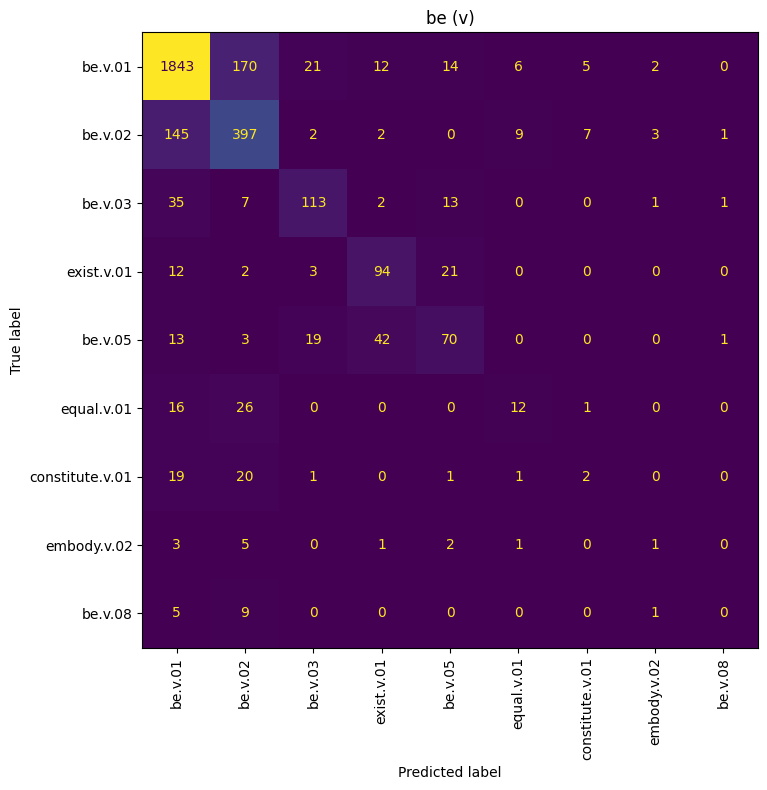

In [27]:
# Inspect a small confusion matrix for the word with the most errors.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

if not errors.empty:
    lemma, pos = errors.groupby(["lemma", "pos"]).size().idxmax()
    examples = results.loc[(results["lemma"] == lemma) & (results["pos"] == pos)]
    gold = examples["true_sense"]
    predicted = examples["predicted_sense"].fillna("__missing__")

    counts = pd.concat([gold, predicted]).value_counts()
    labels = counts.head(12).index.tolist()
    if len(counts) > 12:
        gold = gold.where(gold.isin(labels), "__other__")
        predicted = predicted.where(predicted.isin(labels), "__other__")
        labels.append("__other__")

    matrix = confusion_matrix(gold, predicted, labels=labels)
    pd.DataFrame(matrix, index=labels, columns=labels).to_csv(
        OUT / "evaluation/confusion_matrix.csv"
    )
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(matrix, display_labels=labels).plot(
        ax=ax, xticks_rotation=90, values_format="d", colorbar=False
    )
    ax.set_title(f"{lemma} ({pos})")
    fig.tight_layout()
    fig.savefig(OUT / "evaluation/confusion_matrix.png", dpi=150)
    plt.show()


### Save the outputs for the future Streamlit application

Keep the whole **artifacts** folder together:

| File or folder | What the application will load |
|---|---|
| encoder/ | The selected fine-tuned BERT weights |
| tokenizer/ | The matching tokenizer |
| wsd_model.joblib | Fitted scaler and lemma/POS classifiers |
| sense_mappings.json | Training sense inventory and definitions |
| run_config.json | Preprocessing, context, pooling, and package versions |

The **data** folder contains the dataset, split indices, and matching embeddings.
The **evaluation** folder contains actual results from this run.
The future application must use the same normalization, target cropping, and pooling functions above.


In [28]:
from importlib.metadata import version
import platform

versions = {}
for package in ["torch", "transformers", "scikit-learn", "numpy", "pandas", "nltk", "joblib"]:
    versions[package] = version(package)

sense_inventory = {}
for key, ids in candidate_ids.items():
    sense_inventory[key[0] + "\t" + key[1]] = [senses[i] for i in ids]

mappings = {
    "lemma_pos_senses": sense_inventory,
    "sense_definitions": {sense: wn.synset(sense).definition() for sense in senses},
    "source": "fit partition only"
}
with open(OUT / "artifacts/sense_mappings.json", "w", encoding="utf-8") as file:
    json.dump(mappings, file, indent=2)


In [29]:
config = {
    "pipeline": "fine-tuned BERT -> StandardScaler -> per-lemma/POS Logistic Regression",
    "source_model": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "layers": [-4, -3, -2, -1],
    "pooling": "mean of target WordPieces",
    "context": "start with target; add nearest fitting words; prefer left on ties",
    "normalization": "NFKC, quote/dash replacements, Treebank punctuation; preserve tokens",
    "token_map": TOKEN_MAP,
    "character_map": {chr(key): value for key, value in CHAR_MAP.items()},
    "zero_wordpieces": "replace token with tokenizer.unk_token",
    "target_span": "zero-based start; exclusive end",
    "satellite_pos": "map s to a",
    "C": C,
    "seed": SEED,
    "epochs": EPOCHS,
    "best_epoch": best_epoch,
    "bert_learning_rate": BERT_LEARNING_RATE,
    "head_learning_rate": HEAD_LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "loss_weight_cap": 3.0,
    "training_partition": "fit",
    "validation_accuracy": float(validation_accuracy),
    "fallback": "WordNet first synset for lemma/POS",
    "wordnet_version": wn.get_version(),
    "python_version": platform.python_version(),
    "versions": versions
}
with open(OUT / "artifacts/run_config.json", "w", encoding="utf-8") as file:
    json.dump(config, file, indent=2)

print("Application files saved in:", OUT / "artifacts")
print("Dataset and embeddings saved in:", OUT / "data")
print("Evaluation results saved in:", OUT / "evaluation")


Application files saved in: /kaggle/working/wsd_simple/artifacts
Dataset and embeddings saved in: /kaggle/working/wsd_simple/data
Evaluation results saved in: /kaggle/working/wsd_simple/evaluation


### Try one new sentence

Supply the exact token position, lemma, and POS.
The helper uses the same encoder, preprocessing, vectors, scaler, and classifiers as evaluation.
For multiword targets, also supply the exclusive target_end.


In [30]:
def disambiguate_tokens(words, target_position, lemma, pos, target_end=None):
    if target_end is None:
        target_end = target_position + 1
    key = (lemma.lower().replace(" ", "_"), "a" if pos == "s" else pos)
    encoded = encode_target(words, target_position, target_end)
    classifier = models.get(key)

    if classifier is None:
        sense = wordnet_first_sense(key)
        source = "wordnet" if sense else "missing"
    else:
        vector = scaler.transform(get_embeddings([encoded]))
        sense = str(classifier.predict(vector)[0])
        source = "single_sense" if isinstance(classifier, DummyClassifier) else "logistic"

    return {"sense": sense, "definition": definition(sense), "source": source}

display(disambiguate_tokens(
    ["He", "deposited", "money", "at", "the", "bank", "."], 5, "bank", "n"
))


{'sense': 'depository_financial_institution.n.01',
 'definition': 'a financial institution that accepts deposits and channels the money into lending activities',
 'source': 'logistic'}

Save a completed Kaggle version and download this notebook with its outputs and the entire
/kaggle/working/wsd_simple folder. Running the notebook creates the trained files; an unexecuted
notebook does not contain trained weights or measured accuracy.

The evaluation uses supplied SemCor lemmas and POS. Automatically identifying these in a future
application can introduce additional errors. Sentence groups are separate, but documents are
not explicitly separated. Historical scores are not directly comparable after dataset changes.
